# **Weather Analysis - Exploratory Data Analysis and Visualization**

Dataset: weather_data.csv (158 daily observations,10 columns)


Tools: NumPy, Pandas, Matplotlib and Seaborn.

A construction firm is planning a 5-month long residential project and needs to understand the weather risks in the area through this exploratory data analysis.  This analysis aims to identify safe working windows, high-risk heat days, months with the most delays, and conditions that may affect material quality, to plan schedules and budgets realistically.

Also analyze daily weather patterns in a region from May to September 2025, by examining key metrics such as Ozone levels, Solar Radiation, Wind Speed and Temperature. It also aims to understand how these features vary across different weather conditions(Sunny, Cloudy, Partly Sunny) and how they trend over time.



## I. Importing Python libraries

In [451]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## II. Loading dataset

In [452]:
df=pd.read_csv('/content/drive/MyDrive/Data_Analytics/weather_data.csv')
df.head()

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S


## III. Data Inspection

In [453]:
df.shape

(161, 10)

In [454]:
df.tail(10)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
151,151,14.0,191.0,14.3,75,9,28,2025,75,S
152,152,18.0,131.0,8.0,76,9,29,2025,76,PS
153,153,20.0,223.0,11.5,68,9,30,2025,68,S
154,154,41.0,190.0,7.4,67,5,1,2025,67,C
155,154,41.0,190.0,7.4,67,5,1,2025,67,C
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C
160,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [455]:
df.dtypes

,0
Unnamed: 0,int64
Ozone,float64
Solar.R,float64
Wind,float64
Temp C,object
Month,object
Day,int64
Year,int64
Temp,int64
Weather,object


In [456]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  161 non-null    int64  
 1   Ozone       123 non-null    float64
 2   Solar.R     154 non-null    float64
 3   Wind        161 non-null    float64
 4   Temp C      161 non-null    object 
 5   Month       161 non-null    object 
 6   Day         161 non-null    int64  
 7   Year        161 non-null    int64  
 8   Temp        161 non-null    int64  
 9   Weather     158 non-null    object 
dtypes: float64(3), int64(4), object(3)
memory usage: 12.7+ KB


In [457]:
df.describe()

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,161.000000,123.000000,154.000000,161.000000,161.000000,161.0,161.000000
mean,80.391304,41.837398,185.642857,9.903106,15.950311,2025.0,77.739130
std,46.121738,32.674343,88.237623,3.503274,9.066285,0.0,9.397155
min,1.000000,1.000000,7.000000,1.700000,1.000000,2025.0,56.000000
25%,41.000000,18.000000,121.750000,7.400000,8.000000,2025.0,72.000000
50%,80.000000,31.000000,195.500000,9.700000,16.000000,2025.0,78.000000
75%,120.000000,62.000000,257.500000,11.500000,24.000000,2025.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2025.0,97.000000


In [458]:
df.describe(include='object')

,Temp C,Month,Weather
count,161,161,158
unique,41,6,3
top,81,9,S
freq,11,35,59


In [459]:
df.columns.to_list()

['Unnamed: 0',
 'Ozone',
 'Solar.R',
 'Wind',
 'Temp C',
 'Month',
 'Day',
 'Year',
 'Temp',
 'Weather']

## IV. Data Cleaning and Transformation

In [460]:
df=df.drop(["Unnamed: 0","Temp C"],axis=1)
df

,Ozone,Solar.R,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2025,67,S
1,36.0,118.0,8.0,5,2,2025,72,C
2,12.0,149.0,12.6,5,3,2025,74,PS
3,18.0,313.0,11.5,5,4,2025,62,S
4,NaN,NaN,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
156,30.0,193.0,6.9,9,26,2025,70,PS
157,NaN,145.0,13.2,9,27,2025,77,S
158,14.0,191.0,14.3,9,28,2025,75,S
159,18.0,131.0,8.0,9,29,2025,76,C


In [461]:
df.loc[df.duplicated()]

,Ozone,Solar.R,Wind,Month,Day,Year,Temp,Weather
84,97.0,272.0,5.7,7,9,2025,92,C
155,41.0,190.0,7.4,5,1,2025,67,C
158,14.0,191.0,14.3,9,28,2025,75,S
160,18.0,131.0,8.0,9,29,2025,76,C


In [462]:
df=df.drop_duplicates(ignore_index=True)

In [463]:
df=df.rename({"Solar.R":"Solar"},axis=1)
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2025,67,S
1,36.0,118.0,8.0,5,2,2025,72,C
2,12.0,149.0,12.6,5,3,2025,74,PS
3,18.0,313.0,11.5,5,4,2025,62,S
4,NaN,NaN,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
152,20.0,223.0,11.5,9,30,2025,68,S
153,41.0,190.0,7.4,5,1,2025,67,C
154,30.0,193.0,6.9,9,26,2025,70,PS
155,NaN,145.0,13.2,9,27,2025,77,S


In [464]:
df.isna().sum()

,0
Ozone,38
Solar,7
Wind,0
Month,0
Day,0
Year,0
Temp,0
Weather,3


In [465]:
df['Ozone'].unique()

array([ 41.,  36.,  12.,  18.,  nan,  28.,  23.,  19.,   8.,   7.,  16.,
        11.,  14.,  34.,   6.,  30.,   1.,   4.,  32.,  45., 115.,  37.,
        29.,  71.,  39.,  21.,  20.,  13., 135.,  49.,  64.,  40.,  77.,
        97.,  85.,  10.,  27.,  48.,  35.,  61.,  79.,  63.,  80., 108.,
        52.,  82.,  50.,  59.,   9.,  78.,  66., 122.,  89., 110.,  44.,
        65.,  22.,  31., 168.,  73.,  76., 118.,  84.,  96.,  91.,  47.,
        24.,  46.])

In [466]:
df['Ozone']=pd.to_numeric(df['Ozone'])
df['Ozone'].median()
df['Ozone']=df['Ozone'].fillna(df['Ozone'].median())

In [467]:
df['Solar'].unique()

array([190., 118., 149., 313.,  nan, 299.,  99.,  19., 194., 256., 290.,
       274.,  65., 334., 307.,  78., 322.,  44.,   8., 320.,  25.,  92.,
        66., 266.,  13., 252., 223., 279., 286., 287., 242., 186., 220.,
       264., 127., 273., 291., 323., 259., 250., 148., 332., 191., 284.,
        37., 120., 137., 150.,  59.,  91., 135.,  47.,  98.,  31., 138.,
       269., 248., 236., 101., 175., 314., 276., 267., 272., 139.,  48.,
       260., 285., 187.,   7., 258., 295., 294.,  81.,  82., 213., 275.,
       253., 254.,  83.,  24.,  77., 255., 229., 207., 222., 192., 157.,
        64.,  71.,  51., 115., 244.,  36., 212., 238., 215., 153., 203.,
       225., 237., 188., 167., 197., 183., 189.,  95., 230., 112., 224.,
        27., 201.,  14.,  49.,  20., 193., 145., 131.])

In [468]:
df['Solar']=pd.to_numeric(df['Solar'])
df["Solar"].mean().round()
df['Solar']=df['Solar'].fillna(df['Solar'].mean())

In [469]:
df['Weather'].unique()

array(['S', 'C', 'PS', nan], dtype=object)

In [470]:
df['Weather']=df['Weather'].fillna(df['Weather'].mode().iloc[0])

In [471]:
df.isna().sum()

,0
Ozone,0
Solar,0
Wind,0
Month,0
Day,0
Year,0
Temp,0
Weather,0


In [472]:
df["Month"].unique()

array(['5', 'May', '6', '7', '8', '9'], dtype=object)

In [473]:
df["Month"].replace({"May":'5'}).unique()

array(['5', '6', '7', '8', '9'], dtype=object)

In [474]:
df["Month"]=df["Month"].replace({"May":'5'})
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.000000,7.4,5,1,2025,67,S
1,36.0,118.000000,8.0,5,2,2025,72,C
2,12.0,149.000000,12.6,5,3,2025,74,PS
3,18.0,313.000000,11.5,5,4,2025,62,S
4,31.0,185.366667,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
152,20.0,223.000000,11.5,9,30,2025,68,S
153,41.0,190.000000,7.4,5,1,2025,67,C
154,30.0,193.000000,6.9,9,26,2025,70,PS
155,31.0,145.000000,13.2,9,27,2025,77,S


In [475]:
df["Date"]=pd.to_datetime(df[["Year","Month","Day"]])

In [476]:
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
0,41.0,190.000000,7.4,5,1,2025,67,S,2025-05-01
1,36.0,118.000000,8.0,5,2,2025,72,C,2025-05-02
2,12.0,149.000000,12.6,5,3,2025,74,PS,2025-05-03
3,18.0,313.000000,11.5,5,4,2025,62,S,2025-05-04
4,31.0,185.366667,14.3,5,5,2025,56,S,2025-05-05
...,...,...,...,...,...,...,...,...,...
152,20.0,223.000000,11.5,9,30,2025,68,S,2025-09-30
153,41.0,190.000000,7.4,5,1,2025,67,C,2025-05-01
154,30.0,193.000000,6.9,9,26,2025,70,PS,2025-09-26
155,31.0,145.000000,13.2,9,27,2025,77,S,2025-09-27


In [477]:
df['Weather']=df['Weather'].map({'S': 'Sunny', 'C': 'Cloudy', 'PS': 'Partly Sunny'})

In [479]:
df["Month"].value_counts().reset_index()

,Month,count
0,9,33
1,5,32
2,7,31
3,8,31
4,6,30


## V. Data Analysis and Visualization

**Weather mapping:**

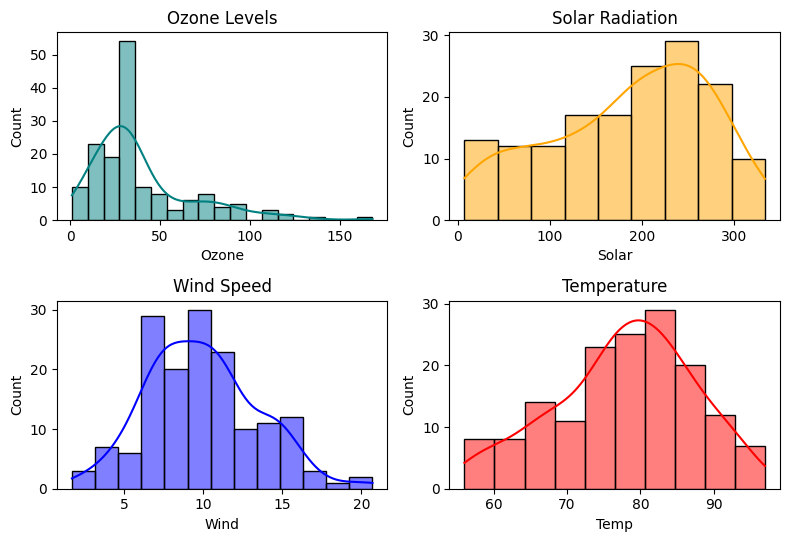

In [498]:
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(8,6))
sns.histplot(ax=axes[0,0],data=df,x='Ozone',kde=True,color='teal').set_title('Ozone Levels')
sns.histplot(ax=axes[0,1],data=df,x='Solar',kde=True,color='orange').set_title('Solar Radiation')
sns.histplot(ax=axes[1,0],data=df,x='Wind',kde=True,color='blue').set_title('Wind Speed')
sns.histplot(ax=axes[1,1],data=df,x='Temp',kde=True,color='red').set_title('Temperature')
plt.tight_layout(rect=[0,0.03,1,0.95])
plt.show()

Insight: Most days have moderate temperatures(around 75-80°F). Extreme heat(above 90°F) is less common but happens. Wind speed is fairly consistent, with most days seeing around 8-12 mph. Ozone and Solar Radiation are "right-skewed." This means most days are relatively clean and not super bright, but there are a handful of days with very high values.

Recommendation: While planning outdoor activities, you can expect moderate weather most days. However, be prepared for occasional extreme heat and high pollution days.

1. When it's hotter, is the air quality worse?

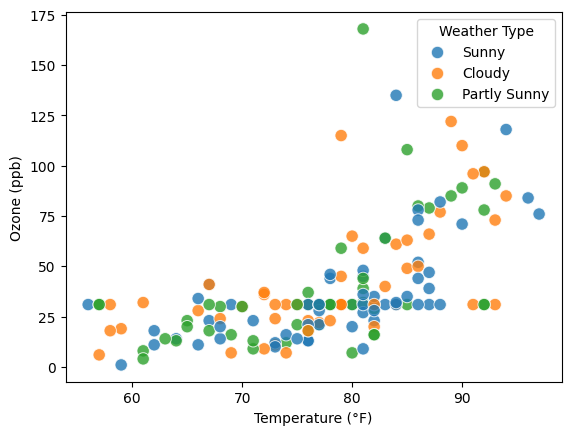

In [496]:
sns.scatterplot(data=df,x='Temp',y='Ozone',hue='Weather',alpha=0.8,s=80)
plt.xlabel('Temperature (°F)')
plt.ylabel('Ozone (ppb)')
plt.legend(title='Weather Type')
plt.show()

Insight: The scatterplot shows a clear pattern where, when temperature goes up, ozone levels also go up. On Sunny, hot days, the ozone is at its highest. On Cloudy, cooler days, the ozone tends to be much lower.

Recommendation: Hot and sunny days are the highest risk for poor air quality. People with respiratory issues should be cautious on these days.

2. Does wind help clear out the pollution?

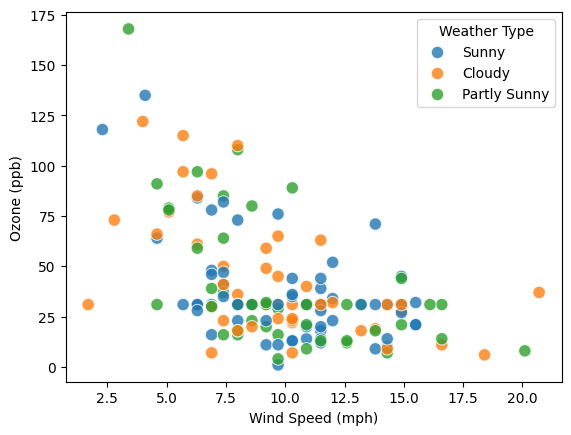

In [501]:
sns.scatterplot(data=df, x='Wind',y='Ozone',hue='Weather',alpha=0.8,s=80)
plt.xlabel('Wind Speed (mph)')
plt.ylabel('Ozone (ppb)')
plt.legend(title='Weather Type')
plt.show()

Insight: There is a strong negative relationship here. On windy days, ozone levels are consistently low. On calm days, ozone can spike. The wind physically blows away the pollutants.

Recommendation: Low-wind days should be flagged as higher pollution risk, even if they are sunny.

3. Which months have the most extreme temperatures?

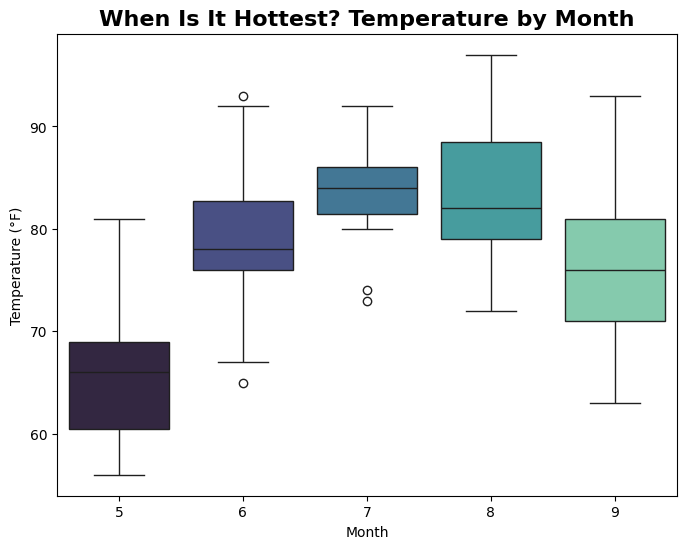

In [511]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df,x='Month',y='Temp',hue='Month',palette='mako',legend=False)
plt.title('When Is It Hottest? Temperature by Month',fontsize=16,fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Temperature (°F)')
plt.show()

Insight: May starts off mild, with most days between 60-70°F. July and August are clearly the hottest months. The median temperature is around 85°F, with many days pushing past 90°F. September begins to cool down slightly but is still quite warm.

Recommendation: For heat-sensitive planning(like construction or outdoor events), July and August are the peak months to prepare for.

4. What is the overall temperature trend across the season?

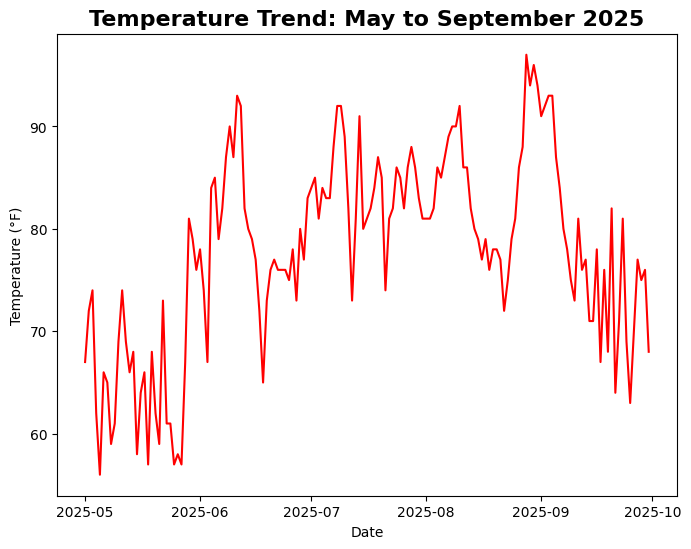

In [514]:
plt.figure(figsize=(8,6))
sns.lineplot(data=df,x='Date',y='Temp',errorbar=None,color='red')
plt.title('Temperature Trend: May to September 2025',fontsize=16,fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Temperature (°F)')
plt.show()

Insight: It shows the "shape" of the summer. It starts cool in May, ramps up through June, peaks in July-August with a lot of volatility and then slowly starts to come down in September.

Recommendation: This confirms a classic summer pattern. The period from July to mid-August is the peak heat season.

5. How many safe working days can we expect per month?

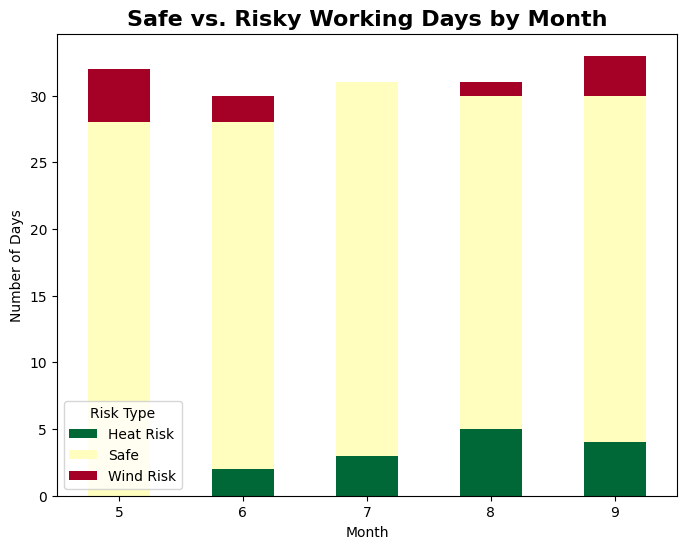

In [532]:
df['Work_Risk']='Safe'
df.loc[(df['Temp'] > 90),'Work_Risk']='Heat Risk'
df.loc[(df['Wind'] > 15),'Work_Risk']='Wind Risk'
df.loc[(df['Temp'] > 90) & (df['Wind']>15),'Work_Risk']='Both Risks'

risk_by_month=df.groupby(['Month','Work_Risk']).size().unstack(fill_value=0)

risk_by_month.plot(kind='bar',stacked=True,figsize=(8,6),colormap='RdYlGn_r')
plt.title('Safe vs. Risky Working Days by Month',fontsize=16,fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Days')
plt.legend(title='Risk Type')
plt.xticks(rotation=0)
plt.show()

Insight: July and August have the most 'Heat Risk' days. May and September are the safest for outdoor work. Wind risk is spread out but peaks in a few specific days.

Recommendation: Schedule critical outdoor work in May, early June, and September. Plan for reduced output in July and August due to heat, and budget extra days for delays.

6. When is the hottest part of the day? which months will slow work down the most?

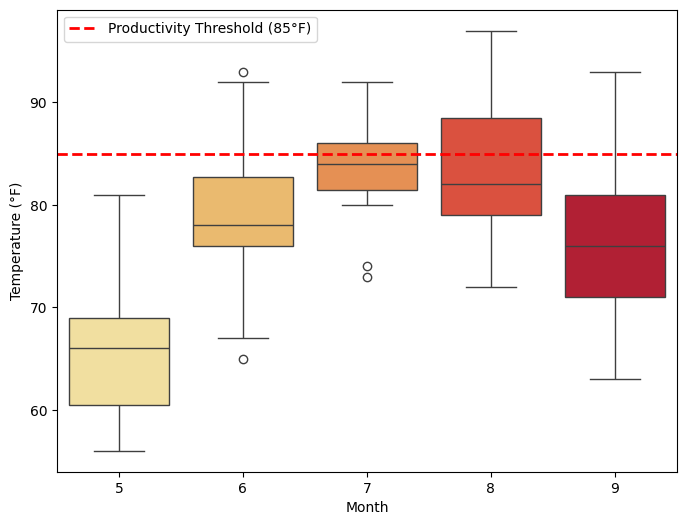

In [534]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df,x='Month',y='Temp',hue='Month',palette='YlOrRd',legend=False)
plt.axhline(y=85,color='red',linestyle='--',linewidth=2,label='Productivity Threshold (85°F)')
plt.xlabel('Month')
plt.ylabel('Temperature (°F)')
plt.legend()
plt.show()

Insight: In July and August, more than half the days exceed the 85°F threshold, meaning worker output will be significantly reduced. May and September are mostly below the threshold.

Recommendation: Build buffer time into the July-August schedule, or plan night shifts and early morning work during those months. Adjust project milestones accordingly.

7. When is the air quality worst, and should we limit outdoor work?

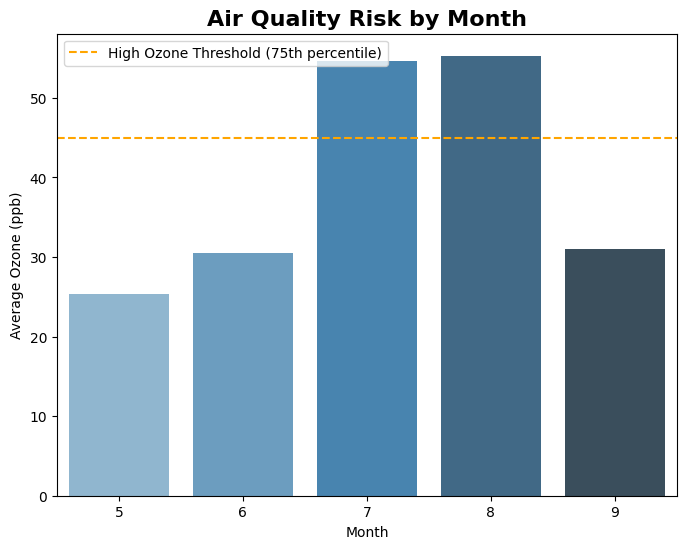

In [536]:
plt.figure(figsize=(8,6))
sns.barplot(data=df,x='Month',y='Ozone',hue='Month',palette='Blues_d',legend=False,errorbar=None)
plt.axhline(y=df['Ozone'].quantile(0.75),color='orange',linestyle='--',label='High Ozone Threshold (75th percentile)')
plt.title('Air Quality Risk by Month', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Ozone (ppb)')
plt.legend()
plt.show()

Insight: Ozone levels are highest in July and August, correlating with the heat. These are the months where outdoor air quality is a risk.

Recommendation: Provide masks and enforce shorter shifts for outdoor workers in July-August. Include air quality advisories in daily site briefings.

8. What's the biggest overall risk driver we should monitor daily?

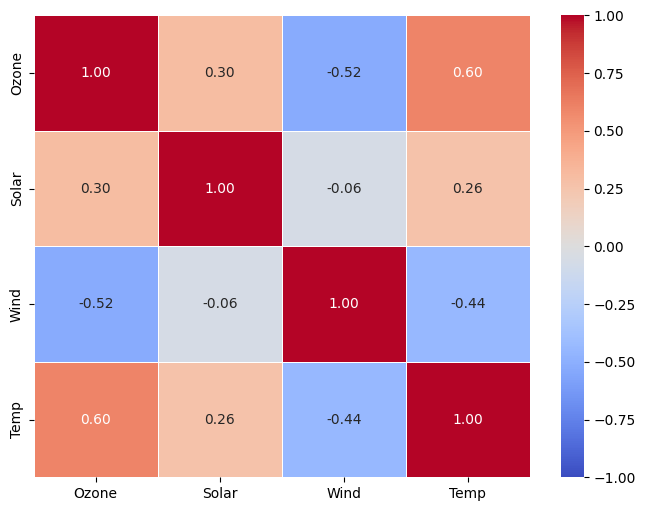

In [518]:
plt.figure(figsize=(8,6))
corr_matrix=df[['Ozone','Solar','Wind','Temp']].corr()
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt=".2f",linewidths=.5,vmin=-1,vmax=1)
plt.show()

Insight: Temperature is the strongest driver of both ozone(0.69) and overall site conditions. Wind is a strong mitigating factor.

Recommendation: The daily monitoring checklist should prioritize Temperature(primary risk) and Wind Speed(relief factor). Ozone can be predicted from these two, so no separate sensor is essential.

## VI. Limitations

The data covers only 158 days in one location and one year, so findings may not apply to other places or time periods.

Some values in Ozone and Solar were missing and filled with averages, which may slightly affect results.

The "risky day" thresholds are general estimates and may not match the actual safety policy.

The dataset lacks rain, humidity, and other weather factors that also affect construction work.

We cannot calculate the actual money lost from delays because the dataset has no cost or productivity information.

## VII. Final Recommendations

Do critical outdoor work in May, early June, and September when most days are safe.

Plan for slow progress in July and August due to heat. Use early morning shifts and add extra days to the schedule.

Monitor temperature and wind speed daily — these are the two most important numbers for site safety.

Don't rely only on the weather label. Always check the actual temperature.

Keep a budget buffer for weather delays, especially in the peak summer months.

## VIII. Conclusion

This project analyzed weather data for a construction company planning work from May to September 2025. The goal was to find safe working days, heat risks, air quality risks, and the main factors affecting site safety.

The results showed that May and September are the best months for outdoor work. July and August are the riskiest due to high heat and poor air quality. Temperature is the most important factor to watch, while wind helps reduce risk on hot days.

This analysis shows how even a small weather dataset can help a company plan better, protect workers and reduce delays. With proper scheduling and daily monitoring, the company can complete the project more safely and efficiently.